## Домашняя мини-задача (5–10 минут)


1) Возьмите **русский роман** (любой .txt) и повторите блок **Zipf + длинный хвост**.
2) Сравните предобработки: lowercasing, удаление пунктуации, замена "ё"→"е", лемматизация (если есть инструменты).
3) Добавьте 2 новых интента и правила (Matcher/regex).


1. загрузка данных

In [1]:
import re
from collections import Counter
import requests
import pandas as pd
from functools import lru_cache
import pymorphy3

In [2]:
url = "https://raw.githubusercontent.com/maurry/nlp/refs/heads/main/Tolstoy_Anna-Karenina_RuLit_Me.txt"

text = requests.get(url).text

Токенизация, types/tokens, частоты

In [3]:
# Простая токенизация для частот: слова из латинских букв + апострофы
tokens = re.findall(r"[А-Яа-я]+(?:'[А-Яа-я]+)?", text.lower())
cnt = Counter(tokens)

N_tokens = sum(cnt.values())  # tokens = все употребления
V_types = len(cnt)            # types  = уникальные слова

print(f"Tokens (всего словоупотреблений): {N_tokens:,}")
print(f"Types  (уникальных слов):        {V_types:,}")

# Топ-20
top20 = cnt.most_common(20)
top20[:10]

Tokens (всего словоупотреблений): 55,033
Types  (уникальных слов):        12,110


[('и', 2626),
 ('в', 1283),
 ('что', 1210),
 ('не', 1207),
 ('он', 944),
 ('она', 718),
 ('на', 699),
 ('с', 697),
 ('я', 602),
 ('как', 530)]

Zipf: rank–frequency (log–log) + топ-20 + длинный хвост ≤ 3

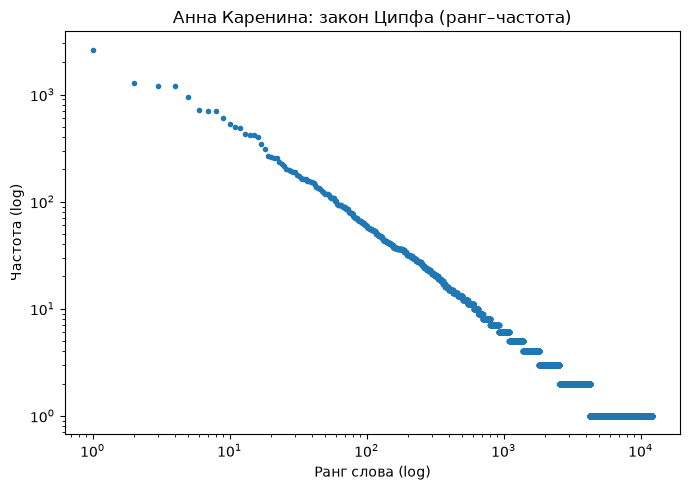

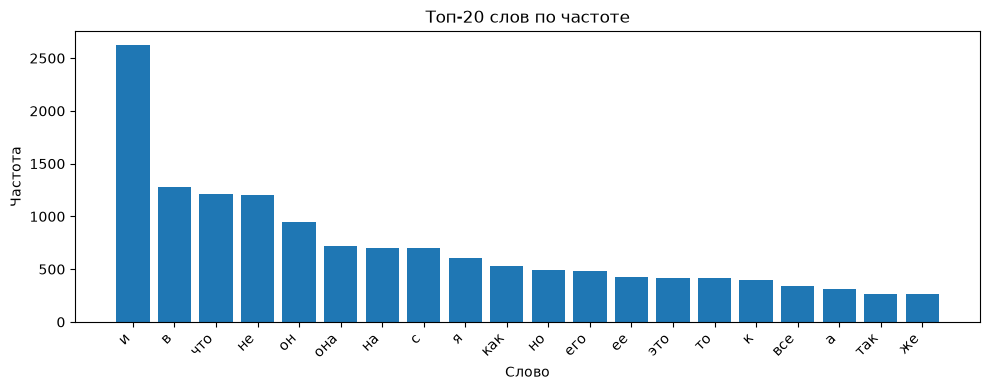

Хвост (c<=3): 10293 типов = 85.0% словаря
Хвост (c<=3): 13476 токенов = 24.5% текста


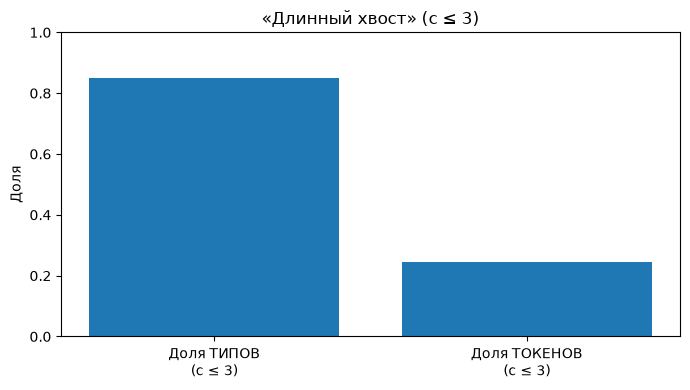

['внимательного',
 'шума',
 'бросающего',
 'вспылил',
 'тоскливое',
 'проявить',
 'решая',
 'портрета',
 'педагогической',
 'отправляется']

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Zipf данные
freqs_sorted = np.array(sorted(cnt.values(), reverse=True))
ranks = np.arange(1, len(freqs_sorted) + 1)

# 3.1 Zipf log-log
plt.figure(figsize=(7,5))
plt.loglog(ranks, freqs_sorted, marker=".", linestyle="none")
plt.title("Анна Каренина: закон Ципфа (ранг–частота)")
plt.xlabel("Ранг слова (log)")
plt.ylabel("Частота (log)")
plt.tight_layout()
plt.show()

# 3.2 Топ-20
df_top20 = pd.DataFrame(top20, columns=["word","count"])
plt.figure(figsize=(10,4))
plt.bar(df_top20["word"], df_top20["count"])
plt.title("Топ-20 слов по частоте")
plt.xlabel("Слово")
plt.ylabel("Частота")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 3.3 Длинный хвост: <= 3
tail_words = [w for w, c in cnt.items() if c <= 3]
tail_types = len(tail_words)
tail_tokens = sum(cnt[w] for w in tail_words)

print(f"Хвост (c<=3): {tail_types} типов = {tail_types/V_types:.1%} словаря")
print(f"Хвост (c<=3): {tail_tokens} токенов = {tail_tokens/N_tokens:.1%} текста")

plt.figure(figsize=(7,4))
plt.bar(["Доля ТИПОВ\n(c ≤ 3)", "Доля ТОКЕНОВ\n(c ≤ 3)"],
        [tail_types/V_types, tail_tokens/N_tokens])
plt.ylim(0, 1)
plt.title("«Длинный хвост» (c ≤ 3)")
plt.ylabel("Доля")
plt.tight_layout()
plt.show()

# 3.4 (Опционально) 10 случайных hapax (c=1)
hapax = [w for w, c in cnt.items() if c == 1]
rng = np.random.default_rng(0)
sample10 = list(rng.choice(hapax, size=10, replace=False))
sample10


2. лемматизация и стемминг, лемматизация через pymorphy3

In [5]:
ru_tokens = re.findall(r"[А-Яа-яЁё]+(?:-[А-Яа-яЁё]+)?", text.lower())
print("Токены:", ru_tokens)

Токены: ['лев', 'николаевич', 'толстой', 'анна', 'каренина', 'работа', 'закипела', 'уже', 'в', 'самом', 'первом', 'наброске', 'были', 'очерчены', 'персонажи', 'в', 'которых', 'можно', 'узнать', 'будущих', 'анну', 'каренина', 'и', 'вронского', 'хотя', 'они', 'еще', 'носили', 'другие', 'имена', 'однако', 'и', 'эти', 'герои', 'и', 'общий', 'смысл', 'романа', 'иные', 'будущий', 'каренин', 'чудак-ученый', 'полный', 'сердечной', 'доброты', 'и', 'невинности', 'милый', 'и', 'кроткий', 'человек', 'страдающее', 'лицо', 'в', 'романе', 'его', 'неверная', 'жена', 'поддалась', 'дьявольскому', 'наваждению', 'в', 'ней', 'проявилось', 'вызывающее', 'и', 'дерзкое', 'начало', 'увлеченная', 'страстью', 'она', 'видит', 'в', 'своем', 'муже', 'только', 'отрицательные', 'качества', 'высший', 'свет', 'изображался', 'сатирически', 'толстой', 'с', 'большим', 'воодушевлением', 'работал', 'над', 'романом', 'быстро', 'создал', 'план', 'и', 'черновые', 'варианты', 'отдельных', 'глав', 'мая', 'года', 'он', 'известил'

In [6]:
import nltk
from nltk.stem.snowball import SnowballStemmer

nltk.download("punkt", quiet=True)
stemmer = SnowballStemmer("russian")

ru_stems = [stemmer.stem(w) for w in ru_tokens]
print(list(zip(ru_tokens, ru_stems)))

[('лев', 'лев'), ('николаевич', 'николаевич'), ('толстой', 'толст'), ('анна', 'ан'), ('каренина', 'каренин'), ('работа', 'работ'), ('закипела', 'закипел'), ('уже', 'уж'), ('в', 'в'), ('самом', 'сам'), ('первом', 'перв'), ('наброске', 'наброск'), ('были', 'был'), ('очерчены', 'очерч'), ('персонажи', 'персонаж'), ('в', 'в'), ('которых', 'котор'), ('можно', 'можн'), ('узнать', 'узна'), ('будущих', 'будущ'), ('анну', 'ан'), ('каренина', 'каренин'), ('и', 'и'), ('вронского', 'вронск'), ('хотя', 'хот'), ('они', 'он'), ('еще', 'ещ'), ('носили', 'нос'), ('другие', 'друг'), ('имена', 'им'), ('однако', 'однак'), ('и', 'и'), ('эти', 'эт'), ('герои', 'геро'), ('и', 'и'), ('общий', 'общ'), ('смысл', 'смысл'), ('романа', 'рома'), ('иные', 'ин'), ('будущий', 'будущ'), ('каренин', 'каренин'), ('чудак-ученый', 'чудак-учен'), ('полный', 'полн'), ('сердечной', 'сердечн'), ('доброты', 'доброт'), ('и', 'и'), ('невинности', 'невин'), ('милый', 'мил'), ('и', 'и'), ('кроткий', 'кротк'), ('человек', 'человек')

In [7]:
import pymorphy3
morph = pymorphy3.MorphAnalyzer()

ru_lemmas_pym = [morph.parse(w)[0].normal_form for w in ru_tokens]
print(list(zip(ru_tokens, ru_lemmas_pym)))

[('лев', 'лев'), ('николаевич', 'николаевич'), ('толстой', 'толстой'), ('анна', 'анна'), ('каренина', 'каренин'), ('работа', 'работа'), ('закипела', 'закипеть'), ('уже', 'уже'), ('в', 'в'), ('самом', 'сам'), ('первом', 'первый'), ('наброске', 'набросок'), ('были', 'быть'), ('очерчены', 'очертить'), ('персонажи', 'персонаж'), ('в', 'в'), ('которых', 'который'), ('можно', 'можно'), ('узнать', 'узнать'), ('будущих', 'будущий'), ('анну', 'анна'), ('каренина', 'каренин'), ('и', 'и'), ('вронского', 'вронский'), ('хотя', 'хотя'), ('они', 'они'), ('еще', 'ещё'), ('носили', 'носить'), ('другие', 'другой'), ('имена', 'имя'), ('однако', 'однако'), ('и', 'и'), ('эти', 'этот'), ('герои', 'герой'), ('и', 'и'), ('общий', 'общий'), ('смысл', 'смысл'), ('романа', 'роман'), ('иные', 'иной'), ('будущий', 'будущий'), ('каренин', 'каренин'), ('чудак-ученый', 'чудак-учёный'), ('полный', 'полный'), ('сердечной', 'сердечный'), ('доброты', 'доброта'), ('и', 'и'), ('невинности', 'невинность'), ('милый', 'милый'

In [8]:
morph = pymorphy3.MorphAnalyzer()

@lru_cache(maxsize=None)
def lemma(w):
    return morph.parse(w)[0].normal_form

raw_tokens = re.findall(r"[А-Яа-яЁё]+(?:-[А-Яа-яЁё]+)*", text)

variants = {
    "регистр сохранён": raw_tokens,
    "lower": [t.lower() for t in raw_tokens],
    "lower + ё→е": [t.lower().replace("ё", "е") for t in raw_tokens],
    "леммы": [lemma(t.lower().replace("ё", "е")) for t in raw_tokens],
}

rows = []
for name, toks in variants.items():
    c = Counter(toks)
    rows.append([name, sum(c.values()), len(c),
                 round(sum(1 for v in c.values() if v <= 3) / len(c), 3),
                 [w for w, _ in c.most_common(5)]])

pd.DataFrame(rows, columns=["вариант", "tokens", "types", "доля types c<=3", "топ-5"])

,вариант,tokens,types,доля types c<=3,топ-5
0,регистр сохранён,54614,12777,0.854,"[и, в, не, что, он]"
1,lower,54614,12160,0.851,"[и, в, не, что, он]"
2,lower + ё→е,54614,12154,0.851,"[и, в, не, что, он]"
3,леммы,54614,6244,0.734,"[и, он, она, в, не]"


3. Matcher, detect_intent, 2 новых правила

In [9]:
import spacy
nlp = spacy.load("ru_core_news_sm")

doc = nlp("Приехав с утренним поездом в Москву, Левин остановился у своего старшего брата по матери Кознышева и, переодевшись, вошел к нему в кабинет, намереваясь тотчас же рассказать ему, для чего он приехал, и просить его совета: но брат был не один. У него сидел известный профессор философии, приехавший из Харькова, собственно, затем, чтобы разъяснить недоразумение, возникшее между ними по весьма важному философскому вопросу. Профессор вел жаркую полемику против материалистов, а Сергей Кознышев синтересом следил за этою полемикой и, прочтя последнюю статью профессора, написал ему в письме свои возражения; он упрекал профессора за слишком большие уступки материалистам. И профессор тотчас же приехал, чтобы столковаться.")
print("SENTENCES:", [s.text for s in doc.sents])
print("TOKENS:", [t.text for t in doc])
print("POS:", [(t.text, t.pos_) for t in doc])
print("DEP:", [(t.text, t.dep_, t.head.text) for t in doc])

print("\nNER entities:")
for ent in doc.ents:
    print(ent.text, ent.label_)

for t in doc:
    print(f"{t.i:2d}  {t.text!r:12}  is_alpha={t.is_alpha}  is_punct={t.is_punct}")


SENTENCES: ['Приехав с утренним поездом в Москву, Левин остановился у своего старшего брата по матери Кознышева и, переодевшись, вошел к нему в кабинет, намереваясь тотчас же рассказать ему, для чего он приехал, и просить его совета: но брат был не один.', 'У\xa0него сидел известный профессор философии, приехавший из Харькова, собственно, затем, чтобы разъяснить недоразумение, возникшее между ними по весьма важному философскому вопросу.', 'Профессор вел жаркую полемику против материалистов, а Сергей Кознышев синтересом следил за этою полемикой и, прочтя последнюю статью профессора, написал ему в письме свои возражения; он упрекал профессора за слишком большие уступки материалистам.', 'И\xa0профессор тотчас же приехал, чтобы столковаться.']
TOKENS: ['Приехав', 'с', 'утренним', 'поездом', 'в', 'Москву', ',', 'Левин', 'остановился', 'у', 'своего', 'старшего', 'брата', 'по', 'матери', 'Кознышева', 'и', ',', 'переодевшись', ',', 'вошел', 'к', 'нему', 'в', 'кабинет', ',', 'намереваясь', 'тот

In [10]:

# Возьмём небольшой фрагмент (чтобы быстро работало)
snippet = " ".join(text.split()[:350])  # первые ~350 слов
doc = nlp(snippet)

# Посмотрим 15 токенов с POS/леммой
rows = []
for t in list(doc)[:15]:
    rows.append([t.text, t.lemma_, t.pos_, t.tag_])
pd.DataFrame(rows, columns=["token","lemma","POS","TAG"])


,token,lemma,POS,TAG
0,Лев,лев,PROPN,PROPN
1,Николаевич,николаевич,PROPN,PROPN
2,Толстой,толстой,PROPN,PROPN
3,Анна,анна,PROPN,PROPN
4,Каренина,каренин,PROPN,PROPN
5,Работа,работа,PROPN,PROPN
6,закипела,закипеть,VERB,VERB
7,.,.,PUNCT,PUNCT
8,Уже,Уже,ADV,ADV
9,в,в,ADP,ADP



Сделаем игрушечный **intent detector** для пользовательских сообщений:
- greeting / goodbye
- ask_weather
- ask_time
- math_addition
- other

Подход:
- регулярки + `spaCy Matcher`.


добавлены два паттерна: thanks, name

In [11]:

from spacy.matcher import Matcher

matcher = Matcher(nlp.vocab)

pattern_greet = [{"LOWER": {"IN": ["привет", "прив", "приветствую", "здравствуй", "здравствуйте", "здарова"]}}]
pattern_goodbye = [{"LOWER": {"IN": ["пока", "до свидания", "всего доброго", "увидимся", "прощай"]}}]
pattern_weather = [{"LOWER": {"IN": ["погода", "дождь", "солнечно", "сыро", "пасмурно", "ветрено"]}}]
pattern_time = [{"LOWER": {"IN": ["время", "час", "часы", "который час"]}}]
pattern_name_1 = [{"LOWER": "как"}, {"LOWER": "ваше"}, {"LOWER": "имя"}]
pattern_name_2 = [{"LOWER": "как"}, {"LOWER": "вас"}, {"LOWER": "зовут"}]
pattern_thanks = [{"LOWER": {"IN": ["спасибо", "благодарю"]}}]

pattern_add_1 = [{"LOWER": "сложи"}, {"IS_DIGIT": True}, {"LOWER": "и"}, {"IS_DIGIT": True}]
pattern_add_2 = [{"LOWER": "сколько"}, {"LOWER": "будет"}, {"IS_DIGIT": True}, {"LOWER": "плюс"}, {"IS_DIGIT": True}]
pattern_add_3 = [{"IS_DIGIT": True}, {"TEXT": "+"}, {"IS_DIGIT": True}]
pattern_goodbye_2 = [{"LOWER": "до"}, {"LOWER": "свидания"}]

matcher.add("GREET", [pattern_greet])
matcher.add("GOODBYE", [pattern_goodbye, pattern_goodbye_2])
matcher.add("WEATHER", [pattern_weather])
matcher.add("TIME", [pattern_time])
matcher.add("ADD", [pattern_add_1, pattern_add_2, pattern_add_3])
matcher.add("NAME", [pattern_name_1, pattern_name_2])
matcher.add("THANKS", [pattern_thanks])

def detect_intent(text: str):
    doc = nlp(text)
    matches = matcher(doc)
    labels = [nlp.vocab.strings[m_id] for m_id, _, _ in matches]

    if "ADD" in labels:
        nums = [int(t.text) for t in doc if t.like_num]
        if len(nums) >= 2:
            return "math_addition", nums[0] + nums[1]
        return "math_addition", None
    if "WEATHER" in labels:
        return "ask_weather", None
    if "TIME" in labels:
        return "ask_time", None
    if "GREET" in labels:
        return "greeting", None
    if "GOODBYE" in labels:
        return "goodbye", None
    if "NAME" in labels:
        return "ask_name", None
    if "THANKS" in labels:
        return "thanks", None
    return "other", None

tests = [
    "Привет!",
    "Здравствуйте, как дела?",
    "Сложи 34957 и 70764",
    "Сколько будет 2 плюс 2?",
    "15 + 3",
    "Какая погода завтра?",
    "Что там с дождём?",
    "Сколько времени?",
    "Который час?",
    "Пока!",
    "До свидания!",
    "Расскажи анекдот",
    "Как ваше имя?",
    "Как вас зовут?",
    "Понял, спасибо",
    "Благодарю за помощь",
]

for s in tests:
    intent, val = detect_intent(s)
    print(f"{s!r} -> {intent}", (f"(value={val})" if val is not None else ""))


'Привет!' -> greeting 
'Здравствуйте, как дела?' -> greeting 
'Сложи 34957 и 70764' -> math_addition (value=105721)
'Сколько будет 2 плюс 2?' -> math_addition (value=4)
'15 + 3' -> math_addition (value=18)
'Какая погода завтра?' -> ask_weather 
'Что там с дождём?' -> other 
'Сколько времени?' -> other 
'Который час?' -> ask_time 
'Пока!' -> goodbye 
'До свидания!' -> goodbye 
'Расскажи анекдот' -> other 
'Как ваше имя?' -> ask_name 
'Как вас зовут?' -> ask_name 
'Понял, спасибо' -> thanks 
'Благодарю за помощь' -> thanks 


## Мини-задача для семинара (русский)

1) Возьмите фрагмент русского романа (например, 30–100k символов).
2) Сравните частоты **по токенам**, **по стеммам**, **по леммам**:
   - Как меняются топ-20?
   - Как меняется доля “длинного хвоста” (≤3) по **types**?
3) Выберите 5 предложений и сравните:
   - POS/DEP/NER от `spaCy`
   - леммы от `pymorphy3`
4) Составьте список имен персонажей
5) Найдите как можно больше предложений, где здороваются


1. фрагмент романа

In [12]:
fragment = text[10000:70000]
print(len(fragment))
print(fragment[:300])


60000
 положение дальше, и усыновить чужого ребенка, и даже дать развод, взяв вину на себя. Герой меняется на глазах, и уже Вронский не понимает, как быть: обманутый муж, смешная фигура в его глазах, приобретает вдруг невиданное величие. Вронский, не в силах смириться с создавшимся положением, предпринима


2. частоты по токенам, стеммам, леммам

In [13]:
from nltk.stem.snowball import SnowballStemmer
stemmer = SnowballStemmer("russian")

toks = [t.lower().replace("ё", "е") for t in re.findall(r"[А-Яа-яЁё]+(?:-[А-Яа-яЁё]+)*", fragment)]
stems = [stemmer.stem(t) for t in toks]
lemmas = [lemma(t) for t in toks]

for name, c in [("токены", Counter(toks)), ("стеммы", Counter(stems)), ("леммы", Counter(lemmas))]:
    V = len(c)
    N = sum(c.values())
    tail = sum(1 for v in c.values() if v <= 3) / V
    print(f"{name}: types={V}, tokens={N}, доля types c≤3={tail:.1%}")
    print("топ-20:", [w for w, _ in c.most_common(20)])
    print()

токены: types=3741, tokens=8706, доля types c≤3=92.1%
топ-20: ['и', 'в', 'не', 'что', 'он', 'с', 'на', 'его', 'как', 'к', 'а', 'но', 'это', 'все', 'то', 'левин', 'для', 'только', 'по', 'ее']

стеммы: types=2490, tokens=8706, доля types c≤3=83.8%
топ-20: ['и', 'в', 'не', 'он', 'что', 'эт', 'с', 'на', 'как', 'ег', 'к', 'был', 'левин', 'котор', 'толст', 'сво', 'а', 'но', 'вронск', 'все']

леммы: types=2499, tokens=8706, доля types c≤3=84.7%
топ-20: ['и', 'в', 'он', 'не', 'что', 'с', 'на', 'быть', 'это', 'она', 'они', 'как', 'к', 'левин', 'который', 'свой', 'толстой', 'этот', 'а', 'но']



3. 5 предложений и сравнение

In [14]:
sentences = [
    "Любовь Анны и Вронского, по Толстому, низший вид любви, греховная плотская любовь.",
    "ВЭкономические вопросы были существенными, но далеко не самыми важными из тех, что волновали автора и героя.",
    "Появление Левина в начале зимы, его частые посещения и явная любовь к Кити были поводом к первым серьезным разговорам между родителями Кити о ее будущности и к спорам между князем и княгинею. ",
    "Тут, глядя на ее стол с лежащим наверху малахитовым бюваром и начатою запиской, мысли его вдруг изменились.",
    "Еще по звуку легких шагов на лестнице он почувствовал ее приближение, и, хотя он был доволен своею речью, ему стало страшно за предстоящее объяснение."
]

In [15]:

for sentence in sentences:
    sentence = nlp(sentence)
    print("ПРЕДЛОЖЕНИЕ:", sentence.text.strip())
    rows = []
    for t in sentence:
        if t.is_space or t.is_punct:
            continue
        rows.append([t.text, t.lemma_, lemma(t.text.lower()), t.pos_, t.dep_, t.head.text])
    display(pd.DataFrame(rows, columns=["токен", "лемма spaCy", "лемма pymorphy3", "POS", "DEP", "head"]))

ПРЕДЛОЖЕНИЕ: Любовь Анны и Вронского, по Толстому, низший вид любви, греховная плотская любовь.


,токен,лемма spaCy,лемма pymorphy3,POS,DEP,head
0,Любовь,любовь,любовь,PROPN,nsubj,любовь
1,Анны,анна,анна,PROPN,nmod,Любовь
2,и,и,и,CCONJ,cc,Вронского
3,Вронского,вронский,вронский,PROPN,conj,Любовь
4,по,по,по,ADP,case,Толстому
5,Толстому,толстой,толстой,PROPN,conj,Любовь
6,низший,низший,низкий,VERB,acl,Любовь
7,вид,вид,вид,NOUN,obj,низший
8,любви,любовь,любовь,NOUN,nmod,вид
9,греховная,греховный,греховный,ADJ,amod,любовь


ПРЕДЛОЖЕНИЕ: ВЭкономические вопросы были существенными, но далеко не самыми важными из тех, что волновали автора и героя.


,токен,лемма spaCy,лемма pymorphy3,POS,DEP,head
0,ВЭкономические,вэкономические,вэкономический,ADJ,amod,вопросы
1,вопросы,вопрос,вопрос,NOUN,nsubj,существенными
2,были,были,быть,AUX,cop,существенными
3,существенными,существенный,существенный,ADJ,ROOT,существенными
4,но,но,но,CCONJ,cc,важными
5,далеко,далеко,далеко,ADV,advmod,не
6,не,не,не,PART,advmod,самыми
7,самыми,самыми,самый,ADJ,amod,важными
8,важными,важный,важный,ADJ,conj,существенными
9,из,из,из,ADP,case,тех


ПРЕДЛОЖЕНИЕ: Появление Левина в начале зимы, его частые посещения и явная любовь к Кити были поводом к первым серьезным разговорам между родителями Кити о ее будущности и к спорам между князем и княгинею.


,токен,лемма spaCy,лемма pymorphy3,POS,DEP,head
0,Появление,появление,появление,NOUN,nsubj,поводом
1,Левина,левин,левин,PROPN,nmod,Появление
2,в,в,в,ADP,case,начале
3,начале,начало,начало,NOUN,nmod,Появление
4,зимы,зима,зима,NOUN,nmod,начале
5,его,он,он,DET,det,посещения
6,частые,частый,частый,ADJ,amod,посещения
7,посещения,посещение,посещение,NOUN,conj,Появление
8,и,и,и,CCONJ,cc,любовь
9,явная,явный,явный,ADJ,amod,любовь


ПРЕДЛОЖЕНИЕ: Тут, глядя на ее стол с лежащим наверху малахитовым бюваром и начатою запиской, мысли его вдруг изменились.


,токен,лемма spaCy,лемма pymorphy3,POS,DEP,head
0,Тут,Тут,тут,ADV,advmod,изменились
1,глядя,глядеть,глядеть,VERB,advcl,изменились
2,на,на,на,ADP,case,стол
3,ее,она,она,DET,det,стол
4,стол,стол,стол,NOUN,obl,глядя
5,с,с,с,ADP,case,бюваром
6,лежащим,лежать,лежать,VERB,acl,бюваром
7,наверху,наверху,наверху,ADV,advmod,лежащим
8,малахитовым,малахитовый,малахитовый,ADJ,amod,бюваром
9,бюваром,бювар,бювар,NOUN,nmod,стол


ПРЕДЛОЖЕНИЕ: Еще по звуку легких шагов на лестнице он почувствовал ее приближение, и, хотя он был доволен своею речью, ему стало страшно за предстоящее объяснение.


,токен,лемма spaCy,лемма pymorphy3,POS,DEP,head
0,Еще,ещё,ещё,ADV,advmod,звуку
1,по,по,по,ADP,case,звуку
2,звуку,звук,звук,NOUN,obl,почувствовал
3,легких,лёгкий,лёгкий,ADJ,amod,шагов
4,шагов,шаг,шаг,NOUN,nmod,звуку
5,на,на,на,ADP,case,лестнице
6,лестнице,лестница,лестница,NOUN,nmod,шагов
7,он,он,он,PRON,nsubj,почувствовал
8,почувствовал,почувствовать,почувствовать,VERB,ROOT,почувствовал
9,ее,она,она,DET,det,приближение


4. имена персонажей

In [16]:
names_text = nlp(text)
persons = [" ".join(lemma(w.lower()) for w in ent.text.split())
           for ent in names_text.ents if ent.label_ == "PER"]

names = Counter(persons)
top_names = [(n, c) for n, c in names.most_common(50) if c >= 2 and len(n) > 2]
pd.DataFrame(top_names, columns=["персонаж", "упоминаний"])

,персонаж,упоминаний
0,левин,239
1,анна,195
2,кить,175
3,вронский,152
4,степан аркадьич,145
5,долли,97
6,толстой,63
7,лёвин,59
8,алексей александрович,50
9,каренин,45


5. приветствия

In [17]:
from spacy.matcher import Matcher

m_ru = Matcher(nlp.vocab)
m_ru.add("GREET_RU", [
    [{"LOWER": {"IN": ["привет", "приветствую", "здравствуй", "здравствуйте"]}}],
    [{"LOWER": "добрый"}, {"LOWER": {"IN": ["день", "вечер", "утро"]}}],
])

hits = [s.text.strip() for s in names_text.sents if len(m_ru(s)) > 0]
print(f"Найдено предложений: {len(hits)}")
for h in hits[:20]:
    print("-", h)

Найдено предложений: 2
- Поцеловав его наконец в покрасневшее от наклоненного положения и сияющее нежностью лицо, девочка разняла руки и хотела бежать назад; но отец удержал ее.
   – Что мама? – сказал отец, водя рукой по гладкой нежной шейке дочери. – Здравствуй, – сказал он, улыбаясь здоровавшемуся мальчику.
- Ах, я уеду сию минуту, если я мешаю.
   – Вы дома там, где вы, баронесса, – сказал Вронский. – Здравствуй, Камеровский, – прибавил он, холодно пожимая руку Камеровского.
   – Вот вы никогда не умеете говорить такие хорошенькие вещи, – обратилась баронесса к Петрицкому.
   – Нет, отчего же?


(как выяснилось, в тексте их действительно очень мало)